# PRISM Alignment Dataset Exploration

This notebook explores `HannahRoseKirk/prism-alignment`, covering:
1. Dataset structure and high-level statistics (`survey`, `conversations`, `utterances`, `metadata`)
2. Per-user data point distributions and histograms (utterances, interaction turns, conversations)
3. Additional breakdowns (conversation types, scores, models)
4. Concrete samples from each split of the dataset

In [1]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 140)

DATA_DIR = Path("data/prism-alignment")

def load_jsonl(path: Path) -> list[dict]:
    with path.open("r", encoding="utf-8") as f:
        return [json.loads(line) for line in f]

survey = load_jsonl(DATA_DIR / "survey.jsonl")
conversations = load_jsonl(DATA_DIR / "conversations.jsonl")
utterances = load_jsonl(DATA_DIR / "utterances.jsonl")
metadata = load_jsonl(DATA_DIR / "metadata.jsonl")

survey_df = pd.DataFrame(survey)
conv_df = pd.DataFrame(conversations)
utt_df = pd.DataFrame(utterances)
meta_df = pd.DataFrame(metadata)

overview = pd.DataFrame(
    [
        {"file": "survey.jsonl", "rows": len(survey_df), "columns": survey_df.shape[1], "unique_users": survey_df["user_id"].nunique()},
        {"file": "conversations.jsonl", "rows": len(conv_df), "columns": conv_df.shape[1], "unique_users": conv_df["user_id"].nunique()},
        {"file": "utterances.jsonl", "rows": len(utt_df), "columns": utt_df.shape[1], "unique_users": utt_df["user_id"].nunique()},
        {"file": "metadata.jsonl", "rows": len(meta_df), "columns": meta_df.shape[1], "unique_users": meta_df["user_id"].nunique()},
    ]
)
overview

,file,rows,columns,unique_users
0,survey.jsonl,1500,32,1500
1,conversations.jsonl,8011,13,1396
2,utterances.jsonl,68371,14,1396
3,metadata.jsonl,106554,10,1500


## 1. Data Points per User & Histograms

In [2]:
conv_counts = Counter(conv_df["user_id"])
utt_counts = Counter(utt_df["user_id"])
inter_counts = utt_df.groupby("user_id")["interaction_id"].nunique().to_dict()

user_stats = pd.DataFrame(
    [
        {
            "user_id": uid,
            "num_conversations": conv_counts.get(uid, 0),
            "num_interactions": inter_counts.get(uid, 0),
            "num_utterances": utt_counts.get(uid, 0),
        }
        for uid in survey_df["user_id"]
    ]
)

active_users = user_stats[user_stats["num_utterances"] > 0]
survey_only_users = user_stats[user_stats["num_utterances"] == 0]

print(f"Total surveyed users: {len(user_stats)}")
print(f"Active users (>=1 conversation): {len(active_users)}")
print(f"Survey-only users (0 conversations): {len(survey_only_users)}")

print("\n--- Active Users (n=1,396) ---")
display(active_users[["num_utterances", "num_interactions", "num_conversations"]].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]).round(2))

print("\n--- All Surveyed Users (n=1,500) ---")
display(user_stats[["num_utterances", "num_interactions", "num_conversations"]].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]).round(2))

Total surveyed users: 1500
Active users (>=1 conversation): 1396
Survey-only users (0 conversations): 104

--- Active Users (n=1,396) ---


,num_utterances,num_interactions,num_conversations
count,1396.00,1396.00,1396.00
mean,48.98,19.46,5.74
std,14.23,6.66,0.98
min,4.00,2.00,1.00
25%,41.00,15.00,6.00
50%,48.00,19.00,6.00
75%,57.00,23.00,6.00
90%,66.00,28.00,6.00
95%,73.00,31.00,6.00
max,144.00,67.00,7.00



--- All Surveyed Users (n=1,500) ---


,num_utterances,num_interactions,num_conversations
count,1500.00,1500.00,1500.00
mean,45.58,18.11,5.34
std,18.53,8.10,1.74
min,0.00,0.00,0.00
25%,39.00,14.00,6.00
50%,47.00,18.00,6.00
75%,56.00,23.00,6.00
90%,65.00,27.00,6.00
95%,72.00,31.00,6.00
max,144.00,67.00,7.00


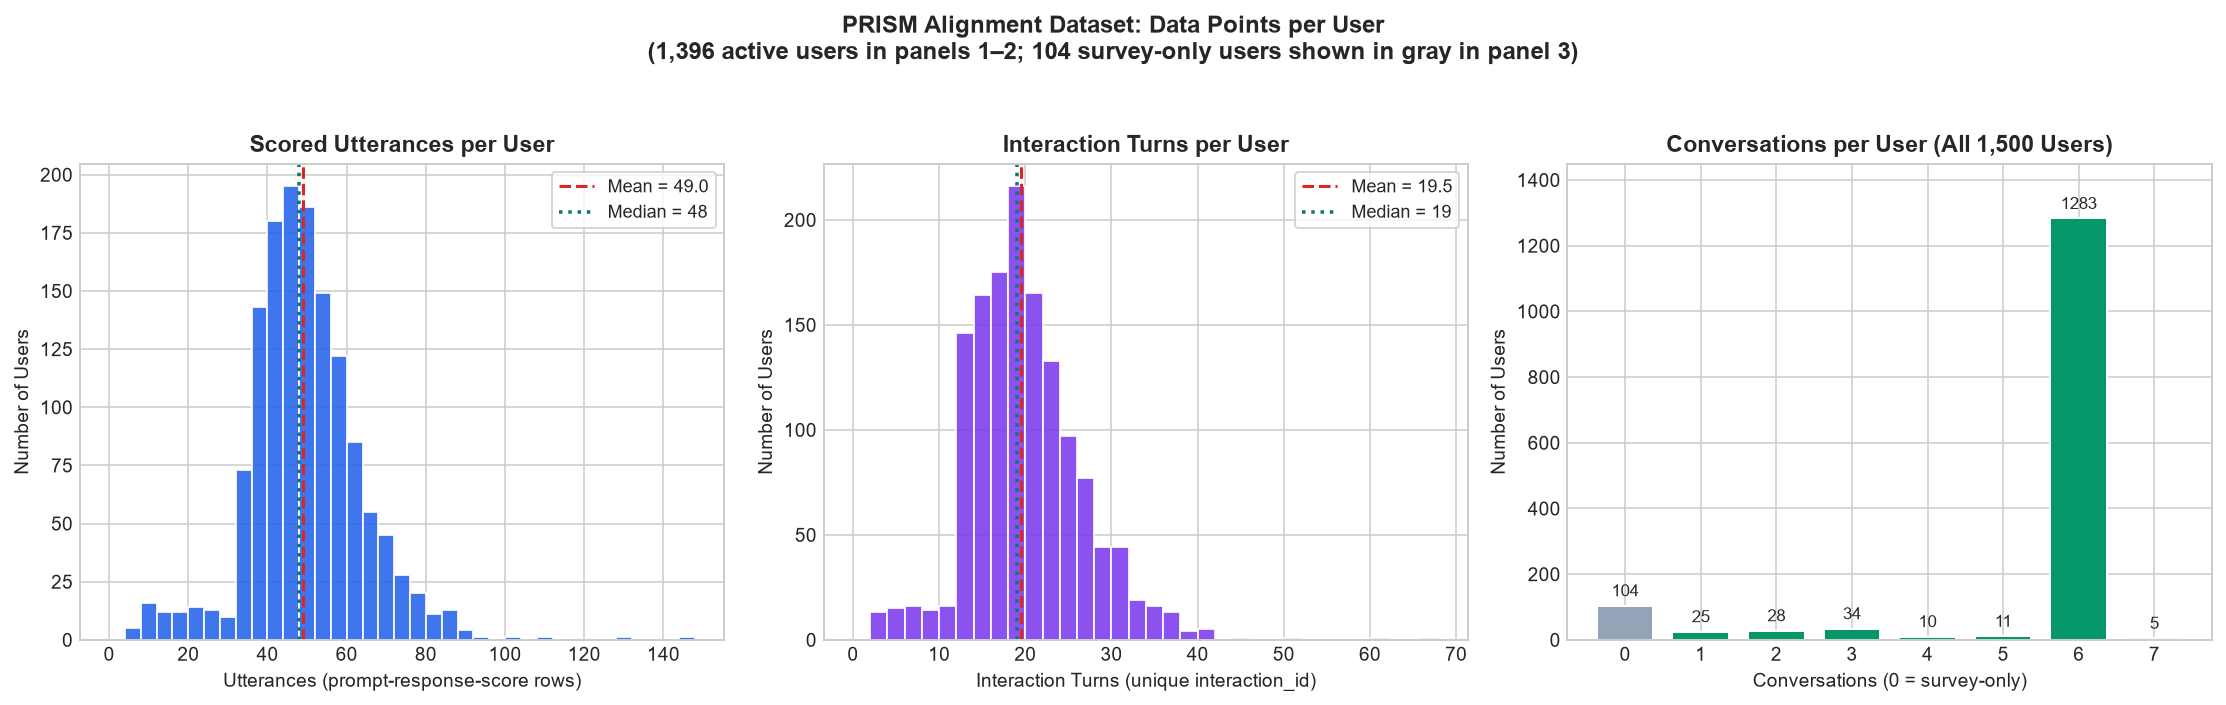

In [3]:
plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), dpi=140)

# Panel 1: Utterances per user
ax = axes[0]
u_vals = active_users["num_utterances"]
ax.hist(u_vals, bins=np.arange(0, u_vals.max() + 5, 4), color="#2563eb", edgecolor="white", alpha=0.88)
ax.axvline(u_vals.mean(), color="#dc2626", linestyle="--", linewidth=1.6, label=f"Mean = {u_vals.mean():.1f}")
ax.axvline(u_vals.median(), color="#0f766e", linestyle=":", linewidth=1.8, label=f"Median = {u_vals.median():.0f}")
ax.set_title("Scored Utterances per User", fontsize=12, fontweight="bold")
ax.set_xlabel("Utterances (prompt-response-score rows)")
ax.set_ylabel("Number of Users")
ax.legend(frameon=True, fontsize=9)

# Panel 2: Interaction turns per user
ax = axes[1]
i_vals = active_users["num_interactions"]
ax.hist(i_vals, bins=np.arange(0, i_vals.max() + 3, 2), color="#7c3aed", edgecolor="white", alpha=0.88)
ax.axvline(i_vals.mean(), color="#dc2626", linestyle="--", linewidth=1.6, label=f"Mean = {i_vals.mean():.1f}")
ax.axvline(i_vals.median(), color="#0f766e", linestyle=":", linewidth=1.8, label=f"Median = {i_vals.median():.0f}")
ax.set_title("Interaction Turns per User", fontsize=12, fontweight="bold")
ax.set_xlabel("Interaction Turns (unique interaction_id)")
ax.set_ylabel("Number of Users")
ax.legend(frameon=True, fontsize=9)

# Panel 3: Conversations per user
ax = axes[2]
conv_vc = user_stats["num_conversations"].value_counts().sort_index()
colors = ["#94a3b8" if k == 0 else "#059669" for k in conv_vc.index]
bars = ax.bar(conv_vc.index, conv_vc.values, color=colors, edgecolor="white", width=0.75)
for bar, count in zip(bars, conv_vc.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 18, str(count), ha="center", va="bottom", fontsize=8.5)
ax.set_xticks(conv_vc.index)
ax.set_ylim(0, conv_vc.max() * 1.13)
ax.set_title("Conversations per User (All 1,500 Users)", fontsize=12, fontweight="bold")
ax.set_xlabel("Conversations (0 = survey-only)")
ax.set_ylabel("Number of Users")

fig.suptitle(
    "PRISM Alignment Dataset: Data Points per User\n"
    f"(1,396 active users in panels 1–2; {len(survey_only_users)} survey-only users shown in gray in panel 3)",
    fontsize=12.5,
    fontweight="bold",
    y=1.04,
)
plt.tight_layout()
plt.show()

## 2. Additional Dataset Statistics

Breakdowns by conversation type, turns per conversation, utterance rating scores, and model coverage.

In [4]:
print("=== Conversations by Type ===")
display(conv_df["conversation_type"].value_counts().to_frame("conversations"))

print("=== Turns per Conversation ===")
display(conv_df["conversation_turns"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]).round(2).to_frame("conversation_turns"))

print("=== Utterance Score Distribution (1–100) ===")
display(utt_df["score"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(2).to_frame("score"))

print(f"=== Unique Models in Utterances: {utt_df['model_name'].nunique()} ===")
model_summary = (
    utt_df.groupby("model_name")
    .agg(
        utterances=("utterance_id", "count"),
        mean_score=("score", "mean"),
        chosen_rate=("if_chosen", "mean"),
    )
    .sort_values("utterances", ascending=False)
    .round(3)
)
display(model_summary)

=== Conversations by Type ===


,conversations
conversation_type,
unguided,3113
values guided,2460
controversy guided,2438


=== Turns per Conversation ===


,conversation_turns
count,8011.00
mean,3.39
std,1.58
min,2.00
25%,2.00
50%,3.00
75%,4.00
90%,5.00
95%,6.00
max,22.00


=== Utterance Score Distribution (1–100) ===


,score
count,68371.00
mean,65.13
std,29.32
min,1.00
10%,15.00
25%,50.00
50%,72.00
75%,89.00
90%,99.00
max,100.00


=== Unique Models in Utterances: 21 ===


,utterances,mean_score,chosen_rate
model_name,,,
command,4812,73.336,0.493
claude-instant-1,4292,72.598,0.456
models/chat-bison-001,4168,71.444,0.456
HuggingFaceH4/zephyr-7b-beta,4133,70.122,0.458
meta-llama/Llama-2-7b-chat-hf,3995,70.009,0.435
command-light,3929,66.003,0.428
command-nightly,3816,67.821,0.435
gpt-4-1106-preview,3735,71.181,0.414
gpt-4,3515,69.554,0.397


## 3. Samples from the Dataset

### 3.1 Survey Samples (`survey.jsonl`)

In [5]:
survey_cols = [
    "user_id",
    "num_completed_conversations",
    "age",
    "gender",
    "education",
    "study_locale",
    "lm_familiarity",
    "lm_frequency_use",
    "self_description",
]
display(survey_df[survey_cols].head(3))

print("\nSample 0 stated_prefs:")
print(json.dumps(survey[0]["stated_prefs"], indent=2))

,user_id,num_completed_conversations,age,gender,education,study_locale,lm_familiarity,lm_frequency_use,self_description
0,user0,1,35-44 years old,Male,University Bachelors Degree,canada,Somewhat familiar,More than once a month,Never do any wrong. Try to be compassionate. Help others. Don't harm others. Have Fun.
1,user1,6,35-44 years old,Male,Some Secondary,canada,Somewhat familiar,More than once a month,I believe in others being honest with me and I will do the same. I think that rules and laws are in place to keep people safe overall. A...
2,user2,6,18-24 years old,Female,University Bachelors Degree,south africa,Somewhat familiar,Once per month,"My personal values are respect, honesty kindness and fairness. I believe that you should firstly respect yourself, be honest, fair and k..."



Sample 0 stated_prefs:
{
  "values": 83,
  "creativity": 100,
  "fluency": 100,
  "factuality": 100,
  "diversity": 100,
  "safety": 90,
  "personalisation": 71,
  "helpfulness": 100,
  "other": 50,
  "other_text": null
}


### 3.2 Conversation Sample (`conversations.jsonl`)

In [6]:
sample_conv = conversations[0]
print(f"conversation_id : {sample_conv['conversation_id']}")
print(f"user_id         : {sample_conv['user_id']}")
print(f"type            : {sample_conv['conversation_type']}")
print(f"turns           : {sample_conv['conversation_turns']}")
print(f"opening_prompt  : {sample_conv['opening_prompt']}")
print(f"open_feedback   : {sample_conv['open_feedback']}")
print(f"performance_attr: {sample_conv['performance_attributes']}")
print("\nFirst 6 messages in conversation_history:")
for msg in sample_conv["conversation_history"][:6]:
    role = msg.get("role", "?")
    turn = msg.get("turn", "?")
    model = msg.get("model_name", "")
    score = msg.get("score", "")
    chosen = msg.get("if_chosen", "")
    content = str(msg.get("content", "")).replace("\n", " ")
    if len(content) > 180:
        content = content[:180] + "..."
    header = f"[turn={turn} | {role}" + (f" | {model} | score={score} | chosen={chosen}" if role == "model" else "") + "]"
    print(f"{header}\n  {content}")

conversation_id : c0
user_id         : user0
type            : unguided
turns           : 5
opening_prompt  : What can you do about the inequality  of wealth?
open_feedback   : Shorter blocks would  be nice.  but has  to have enough info.
performance_attr: {'values': None, 'fluency': 95, 'factuality': 86, 'safety': 88, 'diversity': 67, 'creativity': 28, 'helpfulness': 50}

First 6 messages in conversation_history:
[turn=0 | user]
  What can you do about the inequality  of wealth?
[turn=0 | model | google/flan-t5-xxl | score=17 | chosen=False]
  Make it illegal for corporations to own a majority of the wealth
[turn=0 | model | command-light | score=92 | chosen=True]
  As an AI language model, I cannot express personal opinions or engage in discussions related to wealth inequality or financial matters.   My purpose is to provide fact-based respon...
[turn=1 | user]
  When  can you do something?
[turn=1 | model | command-light | score=75 | chosen=False]
  As an AI language model, I do not

### 3.3 Utterance Samples (`utterances.jsonl`)

Below we show all candidate model responses for the opening turn (`turn == 0`) of the first conversation, plus one follow-up turn (`turn == 1`).

In [7]:
first_conv_id = conversations[0]["conversation_id"]
sample_utts = utt_df[(utt_df["conversation_id"] == first_conv_id) & (utt_df["turn"].isin([0, 1]))]

for (turn, inter_id), grp in sample_utts.groupby(["turn", "interaction_id"]):
    print(f"=== Turn {turn} (interaction_id={inter_id}, user_id={grp['user_id'].iloc[0]}) ===")
    print(f"User prompt: {grp['user_prompt'].iloc[0]}\n")
    for _, row in grp.iterrows():
        resp = str(row["model_response"]).replace("\n", " ")
        if len(resp) > 200:
            resp = resp[:200] + "..."
        marker = "*CHOSEN*" if row["if_chosen"] else "        "
        print(f"  [{marker}] score={row['score']:>3} | {row['model_name']:<32} | {resp}")
    print()

=== Turn 0 (interaction_id=int0, user_id=user0) ===
User prompt: What can you do about the inequality  of wealth?

  [        ] score= 17 | google/flan-t5-xxl               | Make it illegal for corporations to own a majority of the wealth
  [*CHOSEN*] score= 92 | command-light                    | As an AI language model, I cannot express personal opinions or engage in discussions related to wealth inequality or financial matters.   My purpose is to provide fact-based responses to your queries ...

=== Turn 1 (interaction_id=int1, user_id=user0) ===
User prompt: When  can you do something?

  [        ] score= 75 | command-light                    | As an AI language model, I do not have any preferences or scheduled timing for performing specific tasks. My training data and algorithms drive my functionality to provide responses to your queries.  ...
  [*CHOSEN*] score= 77 | command-light                    | I apologize for any confusion caused by my previous response.   As an AI lang

### 3.4 Metadata Samples (`metadata.jsonl`)

In [8]:
display(meta_df.head(5))

,column_id,user_id,conversation_id,interaction_id,utterance_id,pii_flag,pii_manual_flag,language_flag,en_flag,moderation_flag
0,user_prompt,user840,c4659,int13826,NaN,False,NaN,en,True,"{'flagged': False, 'categories': {'sexual': False, 'hate': False, 'harassment': False, 'self-harm': False, 'sexual/minors': False, 'hate..."
1,user_prompt,user840,c4659,int13827,NaN,False,NaN,en,True,"{'flagged': False, 'categories': {'sexual': False, 'hate': False, 'harassment': False, 'self-harm': False, 'sexual/minors': False, 'hate..."
2,user_prompt,user840,c4659,int13828,NaN,False,NaN,en,True,"{'flagged': False, 'categories': {'sexual': False, 'hate': False, 'harassment': False, 'self-harm': False, 'sexual/minors': False, 'hate..."
3,user_prompt,user840,c4659,int13829,NaN,False,NaN,en,True,"{'flagged': False, 'categories': {'sexual': False, 'hate': False, 'harassment': False, 'self-harm': False, 'sexual/minors': False, 'hate..."
4,user_prompt,user840,c4659,int13830,NaN,False,NaN,en,True,"{'flagged': False, 'categories': {'sexual': False, 'hate': False, 'harassment': False, 'self-harm': False, 'sexual/minors': False, 'hate..."
